# Hurst Regimes 02 — roughness of price and volatility (descriptive)

**Discussion:** `discussions/Hurst_Regimes/003_claude_02_roughness_design.md` · **Code:** `src/data_engineering/modeling/hurst_roughness.py`

No trading claim and no gate. All two years of 5-minute history.

1. **Price scaling.** $m_q(\Delta)=\overline{|X_{t+\Delta}-X_t|^q}\propto\Delta^{\zeta(q)}$, with $H=\zeta(2)/2$ fitted separately at 5–30 min, 1–8 h and 1–7 days.
2. **Volatility roughness.** $\log\sigma=\tfrac12\log RV$ on 1h, 4h and 1d blocks (sub-daily blocks deseasonalized).
   - Structure functions and $\zeta(q)$ across $q$; a constant $H_q$ is the monofractal signature.
   - $H$ is reported raw and noise-corrected ($m_2=A\Delta^{2H}+2\eta^2$), then **calibrated by simulation**. Daily RV integration biases $H$ up; RV measurement noise biases it down. Rough-volatility paths with known $H$, the asset's vol-of-vol and the same sample length map estimates back to the true $H$.
3. **Mean reversion of $\log\sigma$.**
   - Autocorrelation: power law vs exponential (OU) decay.
   - fOU fit with the thesis estimators ($\hat\kappa$ from the stationary variance) and its half-life, using the calibrated $H$; the raw COF version is shown for comparison (on log RV, COF is biased upward by block integration).
4. **Stability:** half-year windows.

Environment (optional): `HR_HISTORY_DIR`, `HR_ASSETS`, `HR02_CAL_REPS` (default 3).

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)
load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import hurst_regimes as hr
from data_engineering.modeling import hurst_roughness as rg

HIST_DIR = Path(os.getenv('HR_HISTORY_DIR', str(DATA_ROOT / 'history' / 'price_5m')))
ASSETS = [x.strip().upper() for x in os.getenv('HR_ASSETS', 'AVAX,BTC,ETH,HYPE,SOL,TRX,XRP').split(',') if x.strip()]
CAL_REPS = int(os.getenv('HR02_CAL_REPS', str(rg.CAL_REPS)))
OUT = PROJECT_ROOT / 'notebooks' / 'Hurst_Regimes' / '02'
OUT.mkdir(parents=True, exist_ok=True)
print('Hurst Regimes 02', rg.VERSION, rg.selftest())
hist = hr.load_history(HIST_DIR, ASSETS)
LP, EXCLUDED = {}, {}
for a in sorted(hist.underlying.unique()):
    lp = rg.price_grid(hist, a)
    days = int(lp.notna().sum() // 288)
    print(f'{a}: {lp.index[0]} -> {lp.index[-1]} | bars {len(lp):,} | missing {lp.isna().mean():.2%} | {days} days of data')
    if days < rg.MIN_DAYS:
        EXCLUDED[a] = days
    else:
        LP[a] = lp
print('Excluded (fewer than', rg.MIN_DAYS, 'days):', EXCLUDED)

Hurst Regimes 02 0.1.1 {'version': '0.1.1', 'fbm_H0.35': 0.352, 'fbm_H0.5': 0.498, 'fbm_H0.65': 0.647, 'noisy_raw_H': 0.047, 'noisy_corrected_H': 0.07, 'roughvol_daily_H': 0.23, 'calibrated_daily_H_true0.1': 0.056, 'ok': True}
AVAX: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
BTC: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
ETH: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
HYPE: 2026-09-24 11:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 4,765 | missing 0.00% | 16 days of data
SOL: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
TRX: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
XRP: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:05:00+00:00 | bars 221,761 | missing 0.00% | 770 days of data
Excl

## 1. Price scaling

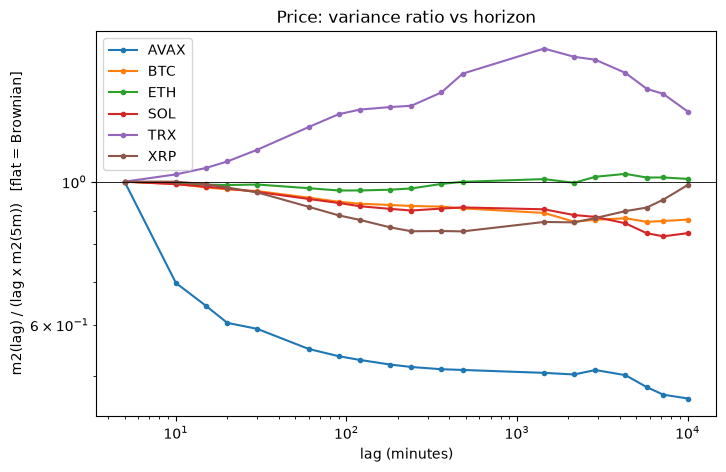

range,5m-30m,1h-8h,1d-7d
underlying,,,
AVAX,0.352,0.482,0.474
BTC,0.490,0.492,0.496
ETH,0.497,0.506,0.502
SOL,0.490,0.492,0.474
TRX,0.531,0.538,0.442
XRP,0.489,0.478,0.533


In [2]:
price_rows, price_sf = [], []
fig, ax = plt.subplots(figsize=(8, 5))
for a, lp in LP.items():
    sf = rg.structure_function(lp.to_numpy(), rg.PRICE_LAGS)
    price_sf.append(sf.assign(underlying=a))
    for rng_name, (lo, hi) in rg.PRICE_RANGES.items():
        z = rg.zeta(sf, lo, hi)
        price_rows.append({'underlying': a, 'range': rng_name, **{k: z[k] for k in ('H2', 'H1', 'zeta2', 'n_lags')}})
    ax.loglog(sf.lag * 5, sf.m2 / sf.m2.iloc[0] / sf.lag, marker='o', ms=3, label=a)
ax.axhline(1, color='k', lw=0.6)
ax.set_xlabel('lag (minutes)'); ax.set_ylabel('m2(lag) / (lag x m2(5m))   [flat = Brownian]')
ax.set_title('Price: variance ratio vs horizon'); ax.legend(); plt.show()
price_tab = pd.DataFrame(price_rows)
display(price_tab.pivot(index='underlying', columns='range', values='H2')[list(rg.PRICE_RANGES)].round(3))

## 2. Volatility roughness

,underlying,block,H_raw,H_noise_corr,H_cof,noise_share_lag1,n_blocks
0,AVAX,1h,0.027,0.030,0.108,0.044,18479
1,AVAX,4h,0.092,0.090,0.238,0.000,4620
2,AVAX,1d,0.094,0.095,0.324,0.000,770
3,BTC,1h,0.089,0.080,0.162,0.000,18479
4,BTC,4h,0.123,0.105,0.266,0.000,4620
5,BTC,1d,0.066,0.990,0.464,0.999,770
6,ETH,1h,0.075,0.070,0.154,0.000,18479
7,ETH,4h,0.111,0.100,0.217,0.000,4620
8,ETH,1d,0.092,0.095,0.400,0.000,770
9,SOL,1h,0.076,0.075,0.145,0.000,18479


Monofractal check: H_q = zeta(q)/q across q (constant across q = monofractal)


,underlying,block,H_q0.5,H_q1,H_q1.5,H_q2,H_q3
0,AVAX,1h,0.042,0.037,0.032,0.027,0.019
1,AVAX,4h,0.096,0.095,0.093,0.092,0.090
2,AVAX,1d,0.111,0.107,0.102,0.094,0.063
3,BTC,1h,0.090,0.090,0.090,0.089,0.086
4,BTC,4h,0.126,0.126,0.125,0.123,0.120
5,BTC,1d,0.069,0.066,0.066,0.066,0.070
6,ETH,1h,0.077,0.077,0.076,0.075,0.073
7,ETH,4h,0.112,0.112,0.112,0.111,0.108
8,ETH,1d,0.106,0.100,0.095,0.092,0.088
9,SOL,1h,0.077,0.076,0.076,0.076,0.074


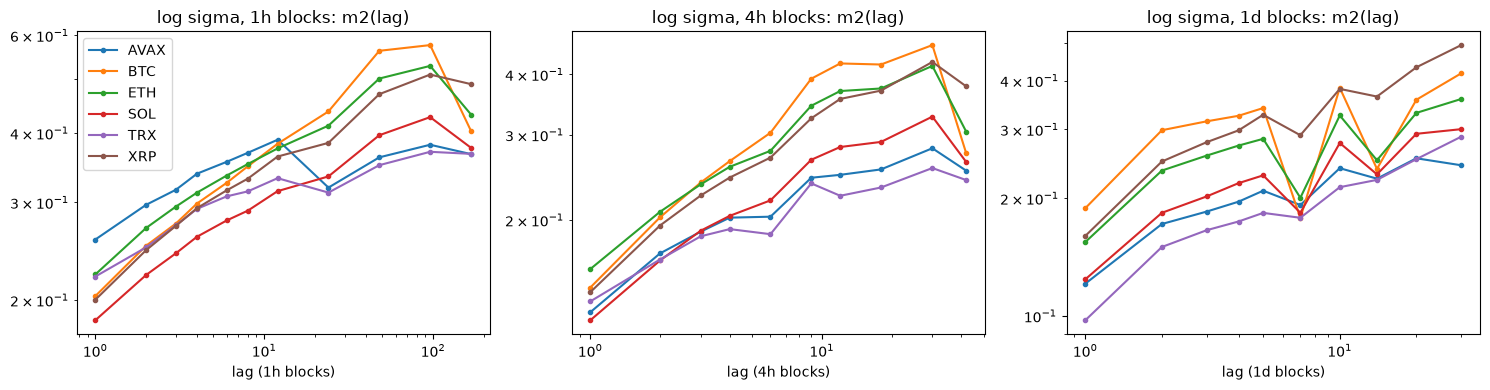

In [3]:
vol_est, vol_rows, zeta_rows, vol_sf = {}, [], [], []
for a, lp in LP.items():
    e = rg.vol_H_estimates(lp, deseason=True)
    vol_est[a] = e
    for b, v in e.items():
        vol_rows.append({'underlying': a, 'block': b, 'H_raw': v['raw'], 'H_noise_corr': v['corr'], 'H_cof': v['cof'],
                         'noise_share_lag1': v['nc'].get('noise_share_lag1', np.nan), 'n_blocks': int(v['lv'].notna().sum())})
        zeta_rows.append({'underlying': a, 'block': b, **{f'H_q{q:g}': v['z'].get(f'H{q:g}', np.nan) for q in rg.QS}})
        vol_sf.append(v['sf'].assign(underlying=a, block=b))
vol_tab = pd.DataFrame(vol_rows)
zeta_tab = pd.DataFrame(zeta_rows)
display(vol_tab.round(3))
print('Monofractal check: H_q = zeta(q)/q across q (constant across q = monofractal)')
display(zeta_tab.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, b in zip(axes, rg.VOL_BLOCKS):
    for a in LP:
        sf = vol_est[a][b]['sf']
        ax.loglog(sf.lag, sf.m2, marker='o', ms=3, label=a)
    ax.set_title(f'log sigma, {b} blocks: m2(lag)'); ax.set_xlabel(f'lag ({b} blocks)')
axes[0].legend(); plt.tight_layout(); plt.show()

## 3. Calibration by simulation (rough-volatility paths with known $H$)

In [4]:
cal_all, cal_rows = [], []
t0 = time.time()
for a, lp in LP.items():
    d1 = vol_est[a]['1d']['sf']
    nu = float(np.sqrt(d1.loc[d1.lag == 1, 'm2'].iloc[0]))         # daily log-vol increment scale (upper bound: includes noise)
    cal = rg.calibrate(len(lp), nu, reps=CAL_REPS)
    cal_all.append(cal.assign(underlying=a, nu=nu))
    for b in rg.VOL_BLOCKS:
        for kind, col in (('raw', 'H_raw'), ('corr', 'H_noise_corr'), ('cof', 'H_cof')):
            h = float(vol_tab.loc[(vol_tab.underlying == a) & (vol_tab.block == b), col].iloc[0])
            cal_rows.append({'underlying': a, 'block': b, 'kind': kind, 'H_est': h, 'H_calibrated': rg.invert(cal, b, kind, h), 'nu': nu})
    print(f'{a}: calibrated ({time.time() - t0:.0f}s)')
cal_df = pd.concat(cal_all, ignore_index=True)
cal_tab = pd.DataFrame(cal_rows)
display(cal_df[cal_df.underlying == list(LP)[0]].pivot_table(index='H_true', columns=['block', 'kind'], values='H_est').round(3))
display(cal_tab.pivot_table(index='underlying', columns=['block', 'kind'], values='H_calibrated').round(3))

AVAX: calibrated (13s)
BTC: calibrated (26s)
ETH: calibrated (40s)
SOL: calibrated (52s)
TRX: calibrated (64s)
XRP: calibrated (76s)


block      1d                   1h                   4h              
kind      cof   corr    raw    cof   corr    raw    cof   corr    raw
H_true                                                               
0.03    0.304  0.152  0.152  0.031  0.030  0.026  0.107  0.077  0.074
0.06    0.308  0.182  0.179  0.050  0.058  0.045  0.166  0.112  0.112
0.10    0.382  0.220  0.218  0.074  0.095  0.069  0.204  0.152  0.151
0.15    0.470  0.253  0.250  0.069  0.150  0.094  0.269  0.195  0.195
0.20    0.496  0.285  0.282  0.052  0.200  0.114  0.279  0.228  0.230
0.30    0.630  0.373  0.371  0.069  0.297  0.153  0.274  0.305  0.297
0.40    0.682  0.443  0.442  0.033  0.387  0.188  0.324  0.377  0.361
0.50    0.723  0.535  0.533  0.025  0.495  0.218  0.263  0.493  0.424

block          1d     1h            4h       
kind          cof   corr    raw   corr    raw
underlying                                   
AVAX        0.068  0.030  0.031  0.041  0.044
BTC         0.140  0.078  0.103  0.042  0.057
ETH         0.106  0.071  0.095  0.044  0.052
SOL         0.087  0.078  0.111  0.057  0.062
TRX         0.123  0.048  0.072  0.041  0.039
XRP         0.110  0.092  0.116  0.073  0.078

## 4. Mean reversion of $\log\sigma$

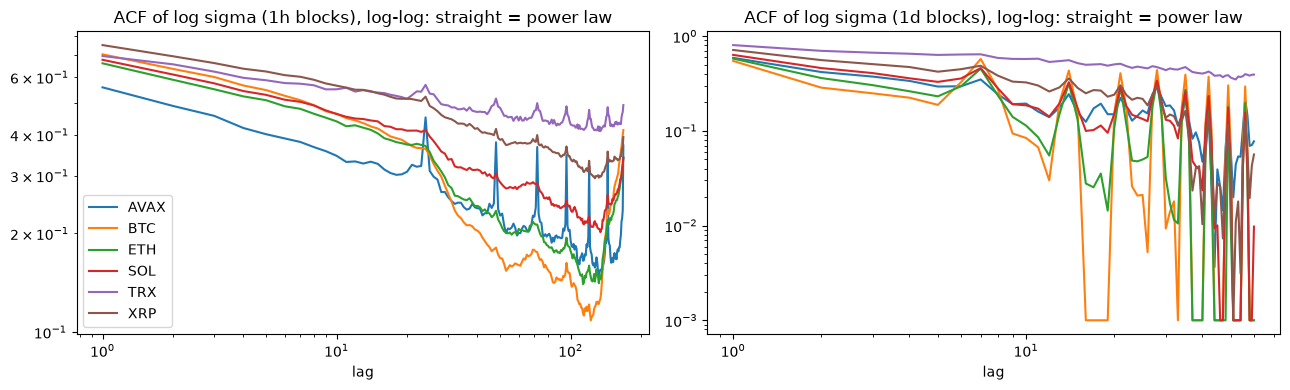

,underlying,block,power_alpha,rss_power,exp_tau,rss_exp,better,n_lags_fit
0,AVAX,1h,0.249,3.530,235.639,5.759,power,168
1,AVAX,1d,0.600,17.040,31.652,16.365,exponential,59
2,BTC,1h,0.317,19.536,272.485,29.350,power,168
3,BTC,1d,0.356,34.456,69.091,36.847,power,38
4,ETH,1h,0.294,7.251,238.230,13.325,power,168
5,ETH,1d,0.607,35.452,36.789,41.292,power,43
6,SOL,1h,0.243,1.835,255.849,4.694,power,168
7,SOL,1d,0.646,17.746,26.526,17.394,exponential,50
8,TRX,1h,0.096,0.269,641.724,0.699,power,168
9,TRX,1d,0.207,0.145,95.944,0.242,power,60


,underlying,block,H_source,H_used,sigma,kappa,half_life_blocks,mean,sd
0,AVAX,4h,calibrated,0.0414,0.3425,0.0000,1.801063e+06,-3.8918,0.4372
1,AVAX,4h,cof_raw (thesis),0.2381,0.3637,0.0834,8.310300e+00,-3.8918,0.4372
2,AVAX,1d,calibrated,0.3238,0.3582,0.2348,2.952600e+00,-3.2352,0.3841
3,AVAX,1d,cof_raw (thesis),0.3238,0.3582,0.2348,2.952600e+00,-3.2352,0.3841
4,BTC,4h,calibrated,0.0417,0.3583,0.0000,3.384714e+07,-4.9046,0.5192
5,BTC,4h,cof_raw (thesis),0.2657,0.3844,0.0699,9.909900e+00,-4.9046,0.5192
6,BTC,1d,calibrated,0.4644,0.4658,0.4761,1.455800e+00,-3.9359,0.4583
7,BTC,1d,cof_raw (thesis),0.4644,0.4658,0.4761,1.455800e+00,-3.9359,0.4583
8,ETH,4h,calibrated,0.0438,0.3806,0.0000,2.033667e+06,-4.5228,0.5049
9,ETH,4h,cof_raw (thesis),0.2165,0.4007,0.0524,1.321600e+01,-4.5228,0.5049


Caveat: kappa = [sigma^2 Gamma(2H+1) / (2 Var)]^(1/(2H)) is extremely sensitive at small H (exponent 1/(2H)); treat half-lives as order-of-magnitude only. The ACF is the model-free read of mean reversion.


In [5]:
acf_rows, fou_rows, acf_curves = [], [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for a in LP:
    for b in ('1h', '1d'):
        lv = vol_est[a][b]['lv'].to_numpy()
        r = rg.acf(lv, rg.ACF_MAX[b])
        acf_curves.append(pd.DataFrame({'underlying': a, 'block': b, 'lag': np.arange(len(r)), 'acf': r}))
        acf_rows.append({'underlying': a, 'block': b, **rg.decay_fits(r, rg.ACF_MAX[b])})
        ax = axes[0] if b == '1h' else axes[1]
        ax.loglog(np.arange(1, len(r)), np.clip(r[1:], 1e-3, None), label=a)
    for b in ('4h', '1d'):
        hc = float(cal_tab.loc[(cal_tab.underlying == a) & (cal_tab.block == b) & (cal_tab.kind == 'corr'), 'H_calibrated'].iloc[0])
        lv = vol_est[a][b]['lv'].to_numpy()
        fou_rows.append({'underlying': a, 'block': b, 'H_source': 'calibrated', **rg.fou_fit(lv, H=hc)})
        fou_rows.append({'underlying': a, 'block': b, 'H_source': 'cof_raw (thesis)', **rg.fou_fit(lv)})
for ax, b in zip(axes, ('1h', '1d')):
    ax.set_title(f'ACF of log sigma ({b} blocks), log-log: straight = power law'); ax.set_xlabel('lag')
axes[0].legend(); plt.tight_layout(); plt.show()
acf_tab, fou_tab = pd.DataFrame(acf_rows), pd.DataFrame(fou_rows)
display(acf_tab.round(3)); display(fou_tab.round(4))
print('Caveat: kappa = [sigma^2 Gamma(2H+1) / (2 Var)]^(1/(2H)) is extremely sensitive at small H (exponent 1/(2H)); '
      'treat half-lives as order-of-magnitude only. The ACF is the model-free read of mean reversion.')

## 5. Stability (half-year windows)

In [6]:
stab = []
for a, lp in LP.items():
    half = lp.index.year.astype(str) + np.where(lp.index.month <= 6, '-H1', '-H2')
    for start, g in lp.groupby(half):
        if g.notna().sum() < 288 * 120:
            continue
        sf = rg.structure_function(g.to_numpy(), rg.PRICE_LAGS)
        lv = rg.log_vol_series(g, 288, deseason=False)
        sfv = rg.structure_function(lv.to_numpy(), rg.VOL_LAGS['1d'])
        lh = rg.log_vol_series(g, 48, deseason=True)
        sfh = rg.structure_function(lh.to_numpy(), rg.VOL_LAGS['4h'])
        stab.append({'underlying': a, 'window': str(start), 'H_price_1h_8h': rg.zeta(sf, 12, 96).get('H2'),
                     'H_price_5m_30m': rg.zeta(sf, 1, 6).get('H2'),
                     'H_vol_1d_raw': rg.zeta(sfv, 1, 30).get('H2'), 'H_vol_4h_corr': rg.noise_corrected_H(sfh, 1, 42).get('H_noise_corr')})
stab_tab = pd.DataFrame(stab)
display(stab_tab.round(3))

,underlying,window,H_price_1h_8h,H_price_5m_30m,H_vol_1d_raw,H_vol_4h_corr
0,AVAX,2024-H2,0.481,0.484,0.142,0.110
1,AVAX,2025-H1,0.503,0.502,0.085,0.110
2,AVAX,2025-H2,0.463,0.181,0.069,0.085
3,AVAX,2026-H1,0.478,0.492,0.120,0.090
4,BTC,2024-H2,0.477,0.494,0.019,0.105
5,BTC,2025-H1,0.501,0.493,0.089,0.140
6,BTC,2025-H2,0.506,0.479,0.047,0.080
7,BTC,2026-H1,0.480,0.491,0.102,0.110
8,ETH,2024-H2,0.476,0.493,0.063,0.095
9,ETH,2025-H1,0.526,0.498,0.104,0.130


## 6. Outputs

In [7]:
price_tab.to_csv(OUT / '02_price_scaling.csv', index=False, float_format='%.5g')
pd.concat(price_sf, ignore_index=True).to_csv(OUT / '02_price_structure.csv', index=False, float_format='%.6g')
vol_tab.merge(zeta_tab, on=['underlying', 'block']).to_csv(OUT / '02_vol_H.csv', index=False, float_format='%.5g')
pd.concat(vol_sf, ignore_index=True).to_csv(OUT / '02_vol_structure.csv', index=False, float_format='%.6g')
cal_df.to_csv(OUT / '02_calibration_map.csv', index=False, float_format='%.5g')
cal_tab.to_csv(OUT / '02_vol_H_calibrated.csv', index=False, float_format='%.5g')
acf_tab.to_csv(OUT / '02_acf_fits.csv', index=False, float_format='%.5g')
pd.concat(acf_curves, ignore_index=True).to_csv(OUT / '02_acf_curves.csv', index=False, float_format='%.5g')
fou_tab.to_csv(OUT / '02_fou_fit.csv', index=False, float_format='%.5g')
stab_tab.to_csv(OUT / '02_stability.csv', index=False, float_format='%.5g')
meta = {'module': '02_roughness', 'version': rg.VERSION, 'assets': list(LP), 'excluded_short_history_days': EXCLUDED, 'cal_reps': CAL_REPS, 'history_dir': str(HIST_DIR),
        'first': str(min(lp.index[0] for lp in LP.values())), 'last': str(max(lp.index[-1] for lp in LP.values()))}
(OUT / '02_run_metadata.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "module": "02_roughness",
  "version": "0.1.1",
  "assets": [
    "AVAX",
    "BTC",
    "ETH",
    "SOL",
    "TRX",
    "XRP"
  ],
  "excluded_short_history_days": {
    "HYPE": 16
  },
  "cal_reps": 3,
  "history_dir": "D:\\MarketData\\Deribit\\history\\price_5m",
  "first": "2024-09-01 00:05:00+00:00",
  "last": "2026-10-11 00:05:00+00:00"
}
